# Lab 4: Basic Quantum Circuits
**Course:** Quantum Computation
**Student:** ยามาอัลลุดดีน เจ๊ะหามะ (AISE, PSU Phuket)

Notebook นี้ครอบคลุม Task 1–5 และ Exercise 1–2 ของ Lab 4

## Task 1 — Setup in Google Colab

In [1]:
!pip install -q qiskit qiskit-aer pylatexenc sympy

In [2]:
import os
os.makedirs('images', exist_ok=True)
from math import pi
import random
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit_aer import Aer
from qiskit.visualization import plot_histogram
from qiskit.quantum_info import Statevector
import qiskit, qiskit_aer
print("qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__)

backend = Aer.get_backend('aer_simulator')

def run_counts(circ, shots=1024, seed=42):
    """Transpile + run a circuit on Aer, return measurement counts."""
    tqc = transpile(circ, backend)
    return backend.run(tqc, shots=shots, seed_simulator=seed).result().get_counts()

qiskit 2.6.1 | qiskit-aer 0.18.2


## Task 2 — Building a Simple Circuit (Bell state)

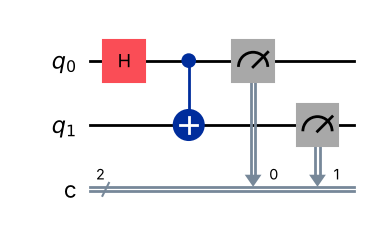

In [3]:
qc = QuantumCircuit(2, 2)
qc.h(0)
qc.cx(0, 1)
qc.measure([0, 1], [0, 1])
fig = qc.draw('mpl')
fig.savefig('images/task2_bell_circuit.png', dpi=150, bbox_inches='tight')
fig

## Task 3 — Simulation with Qiskit Aer

Counts: {'11': 503, '00': 521}
  P(00) ≈ 0.509
  P(11) ≈ 0.491


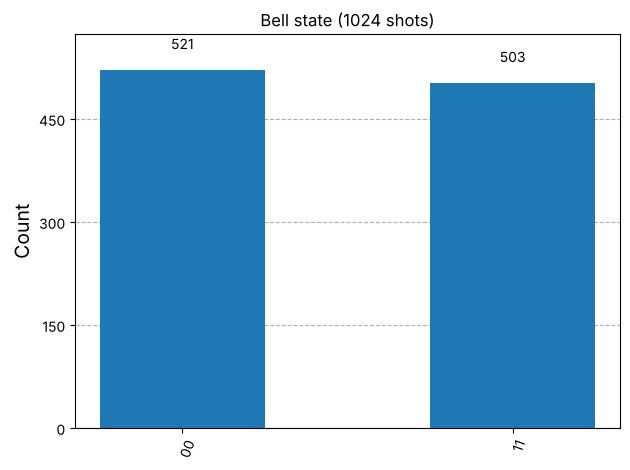

In [4]:
counts = run_counts(qc)
print("Counts:", counts)
for k, v in sorted(counts.items()):
    print(f"  P({k}) ≈ {v/1024:.3f}")
fig = plot_histogram(counts, title="Bell state (1024 shots)")
fig.savefig('images/task3_bell_hist.png', dpi=150, bbox_inches='tight')
fig

## Task 4 — Statevector Simulation

In [5]:
qc_sv = QuantumCircuit(2)
qc_sv.h(0)
qc_sv.cx(0, 1)

state = Statevector.from_instruction(qc_sv)
print(state)
print("Probabilities:", state.probabilities_dict())
state.draw('latex')

Statevector([0.70710678+0.j, 0.        +0.j, 0.        +0.j,
             0.70710678+0.j],
            dims=(2, 2))
Probabilities: {np.str_('00'): np.float64(0.4999999999999999), np.str_('11'): np.float64(0.4999999999999999)}


<IPython.core.display.Latex object>

## Task 5 — Adding More Layers

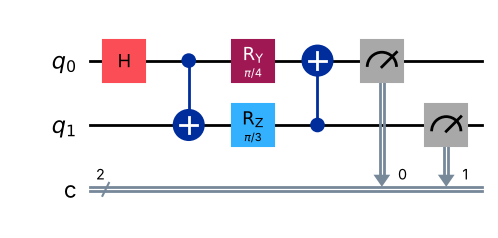

In [6]:
qc2 = QuantumCircuit(2, 2)
qc2.h(0)
qc2.cx(0, 1)
qc2.ry(pi/4, 0)
qc2.rz(pi/3, 1)
qc2.cx(1, 0)
qc2.measure([0, 1], [0, 1])
fig = qc2.draw('mpl')
fig.savefig('images/task5_layers_circuit.png', dpi=150, bbox_inches='tight')
fig

Theory : {np.str_('00'): np.float64(0.4268), np.str_('01'): np.float64(0.0732), np.str_('10'): np.float64(0.4268), np.str_('11'): np.float64(0.0732)}
Counts : {'11': 62, '01': 90, '00': 436, '10': 436}
Depth  : 5


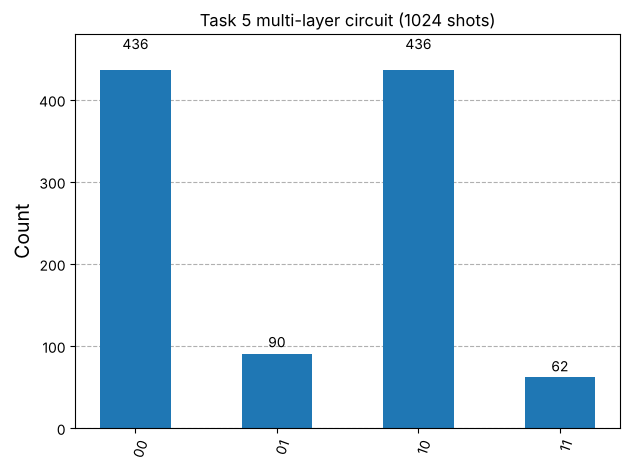

In [7]:
# Theoretical probabilities (same circuit without measurement)
qc2_sv = qc2.remove_final_measurements(inplace=False)
sv2 = Statevector.from_instruction(qc2_sv)
print("Theory :", {k: round(v, 4) for k, v in sv2.probabilities_dict().items()})

counts2 = run_counts(qc2)
print("Counts :", counts2)
print("Depth  :", qc2.depth())
fig = plot_histogram(counts2, title="Task 5 multi-layer circuit (1024 shots)")
fig.savefig('images/task5_layers_hist.png', dpi=150, bbox_inches='tight')
fig

## Exercise 1 — Three-Qubit GHZ Circuit
เป้าหมาย: |000⟩ → (|000⟩ + |111⟩)/√2
แนวคิด: H บน q0 สร้าง superposition แล้วใช้ CNOT ส่งต่อ "สถานะเดียวกัน" ไปยัง q1 และ q2

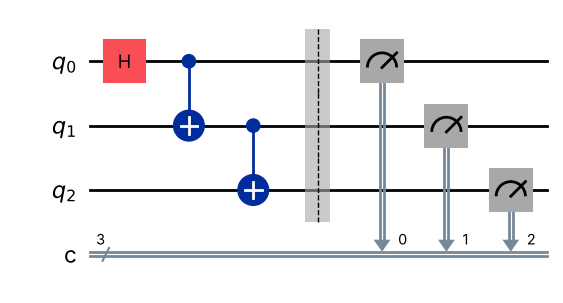

In [8]:
ghz = QuantumCircuit(3, 3)
ghz.h(0)
ghz.cx(0, 1)
ghz.cx(1, 2)
ghz.barrier()
ghz.measure([0, 1, 2], [0, 1, 2])
fig = ghz.draw('mpl')
fig.savefig('images/ex1_ghz_circuit.png', dpi=150, bbox_inches='tight')
fig

Statevector([0.70710678+0.j, 0.        +0.j, 0.        +0.j,
             0.        +0.j, 0.        +0.j, 0.        +0.j,
             0.        +0.j, 0.70710678+0.j],
            dims=(2, 2, 2))
Probabilities: {np.str_('000'): np.float64(0.4999999999999999), np.str_('111'): np.float64(0.4999999999999999)}
Counts: {'000': 490, '111': 534}


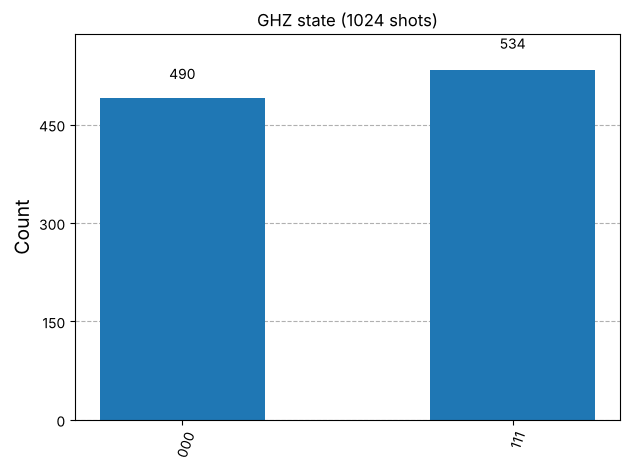

In [9]:
ghz_sv = Statevector.from_instruction(ghz.remove_final_measurements(inplace=False))
print(ghz_sv)
print("Probabilities:", ghz_sv.probabilities_dict())

ghz_counts = run_counts(ghz)
print("Counts:", ghz_counts)
fig = plot_histogram(ghz_counts, title="GHZ state (1024 shots)")
fig.savefig('images/ex1_ghz_hist.png', dpi=150, bbox_inches='tight')
fig

## Exercise 2 — Random 3-Qubit Circuit
สุ่มเกตจาก {H, X, Z, CX} 10 ครั้ง (ใช้ seed เพื่อให้ผลซ้ำได้)

Gate sequence: Z(q0) , CX(2->0) , H(q2) , H(q1) , H(q2) , X(q0) , H(q1) , CX(0->2) , H(q2) , CX(0->2)


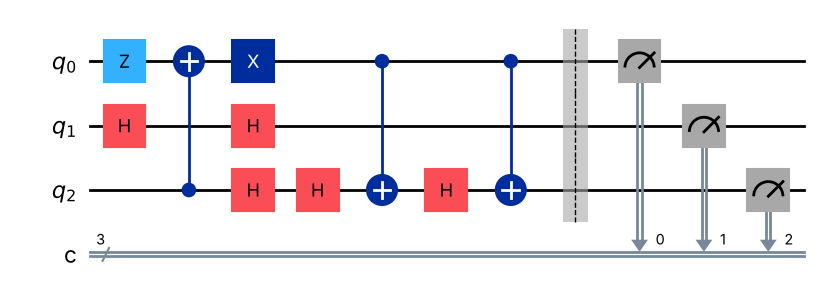

In [10]:
random.seed(7)
rand_qc = QuantumCircuit(3, 3)
log = []
for _ in range(10):
    g = random.choice(['h', 'x', 'z', 'cx'])
    if g == 'cx':
        c, t = random.sample(range(3), 2)
        rand_qc.cx(c, t); log.append(f"CX({c}->{t})")
    else:
        q = random.randrange(3)
        getattr(rand_qc, g)(q); log.append(f"{g.upper()}(q{q})")
print("Gate sequence:", " , ".join(log))

rand_nom = rand_qc.copy()
rand_qc.barrier()
rand_qc.measure([0, 1, 2], [0, 1, 2])
fig = rand_qc.draw('mpl')
fig.savefig('images/ex2_random_circuit.png', dpi=150, bbox_inches='tight')
fig

Statevector([-0.00000000e+00+0.j, -7.07106781e-01+0.j, -0.00000000e+00+0.j,
             -4.40052725e-19+0.j, -0.00000000e+00+0.j,  7.07106781e-01+0.j,
             -0.00000000e+00+0.j,  4.40052725e-19+0.j],
            dims=(2, 2, 2))
Theory : {np.str_('001'): np.float64(0.5), np.str_('011'): np.float64(0.0), np.str_('101'): np.float64(0.5), np.str_('111'): np.float64(0.0)}


Counts : {'001': 526, '101': 498}
Depth  : 7


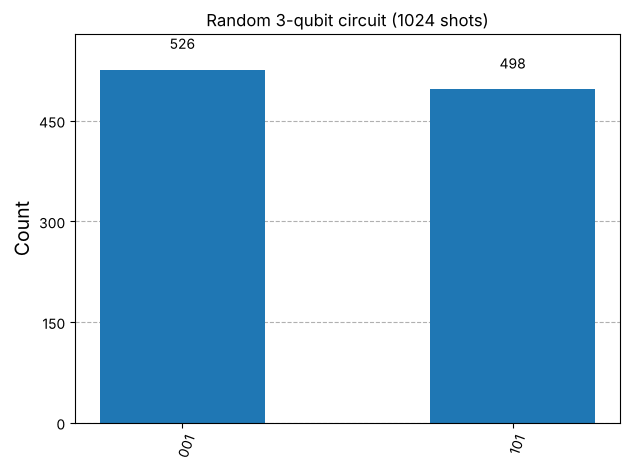

In [11]:
rand_sv = Statevector.from_instruction(rand_nom)
print(rand_sv)
print("Theory :", {k: round(v, 4) for k, v in rand_sv.probabilities_dict().items()})
rand_counts = run_counts(rand_qc)
print("Counts :", rand_counts)
print("Depth  :", rand_nom.depth())
fig = plot_histogram(rand_counts, title="Random 3-qubit circuit (1024 shots)")
fig.savefig('images/ex2_random_hist.png', dpi=150, bbox_inches='tight')
fig

In [12]:
# Step-by-step trace: statevector after each gate (ใช้อธิบายผล)
sv = Statevector.from_label('000')
for inst, name in zip(rand_nom.data, log):
    sv = sv.evolve(inst.operation, [rand_nom.find_bit(q).index for q in inst.qubits])
    terms = [f"{amp.real:+.3f}{amp.imag:+.3f}j|{k}>" if abs(amp.imag)>1e-9 else f"{amp.real:+.3f}|{k}>"
             for k, amp in sv.to_dict().items() if abs(amp) > 1e-9]
    print(f"{name:10s} -> " + " ".join(terms))

Z(q0)      -> +1.000|000>
CX(2->0)   -> +1.000|000>
H(q2)      -> +0.707|000> +0.707|100>
H(q1)      -> +0.500|000> +0.500|010> +0.500|100> +0.500|110>
H(q2)      -> +0.707|000> +0.707|010>
X(q0)      -> +0.707|001> +0.707|011>
H(q1)      -> +1.000|001>
CX(0->2)   -> +1.000|101>
H(q2)      -> +0.707|001> -0.707|101>
CX(0->2)   -> -0.707|001> +0.707|101>


## Extra — Order Matters & Circuit Depth (ประกอบ Concept Questions)

In [13]:
a = QuantumCircuit(1); a.h(0); a.x(0)   # X·H|0>
b = QuantumCircuit(1); b.x(0); b.h(0)   # H·X|0>
print("H then X:", Statevector.from_instruction(a))
print("X then H:", Statevector.from_instruction(b))

ghz_nom = ghz.remove_final_measurements(inplace=False)
ghz_fan = QuantumCircuit(3); ghz_fan.h(0); ghz_fan.cx(0, 1); ghz_fan.cx(0, 2)
print("GHZ chain depth:", ghz_nom.depth(), "| GHZ fan-out depth:", ghz_fan.depth())
print("Same state?", Statevector.from_instruction(ghz_nom).equiv(Statevector.from_instruction(ghz_fan)))

H then X: Statevector([0.70710678+0.j, 0.70710678+0.j],
            dims=(2,))
X then H: Statevector([ 0.70710678+0.j, -0.70710678+0.j],
            dims=(2,))
GHZ chain depth: 3 | GHZ fan-out depth: 3
Same state? True
